# Begin

Nicholas Alan Gilbert Emperical Exercise #2 10-26-26

### Table of Contents

[Set Up](#Set-Up)

[Data Handling](#Data-Handling)

[Task 1](#Task-1) - Compute Log Returns

[Task 2](#Task-2) - Annaulized Returns

[Task 3](#Task-3) - Data Visualization 

# Set Up

We will import necessary libraries and custom helper-functions written in another file.

In [1]:
%load_ext autoreload
%autoreload 2

import yfinance as yf
import pandas as pd
import matplotlib.pyplot as plt
import scipy.stats as st
import numpy as np
import ipywidgets

#Custom Helper Functions
import helper.tools as tools

In [3]:
stocks = tools.StockSearch()

In [13]:
stocks.start

datetime.date(2000, 1, 1)

In [14]:
stocks.end

datetime.date(2026, 10, 26)

In [18]:
stocks.tickers = ['XLC', 'XLY', 'XLP', 'XLE', 'XLF', 'XLV', 'XLI', 'XLB', 'XLRE', 'XLK', 'XLU']

stocks.tickers

['XLC', 'XLY', 'XLP', 'XLE', 'XLF', 'XLV', 'XLI', 'XLB', 'XLRE', 'XLK', 'XLU']

In [19]:
df = stocks.data.copy()

[*********************100%***********************]  11 of 11 completed


In [20]:
df

Price           Close                                                \
Ticker            XLB         XLC        XLE        XLF         XLI   
Date                                                                  
2000-01-03   7.168345         NaN   6.569214  11.013208   17.982185   
2000-01-04   7.099332         NaN   6.445558  10.531755   17.485386   
2000-01-05   7.392622         NaN   6.615584  10.449008   17.407461   
2000-01-06   7.582393         NaN   6.870625  10.907898   17.641241   
2000-01-07   7.578085         NaN   6.944041  11.088442   18.313396   
...               ...         ...        ...        ...         ...   
2026-10-19  50.950001  110.089996  67.800003  55.060001  166.679993   
2026-10-20  51.230000  110.190002  67.970001  55.720001  166.800003   
2026-10-21  51.320000  108.970001  68.160004  56.040001  168.309998   
2026-10-22  51.689999  107.419998  67.570000  56.650002  166.729996   
2026-10-23  51.310001  105.510002  69.330002  55.900002  164.619995   

Price                                                                ...  \
Ticker             XLK        XLP       XLRE        XLU         XLV  ...   
Date                                                                 ...   
2000-01-03   20.577808  11.976411        NaN   5.438091   20.273394  ...   
2000-01-04   19.533834  11.639163        NaN   5.274050   19.813354  ...   
2000-01-05   19.243847  11.844800        NaN   5.407141   19.635611  ...   
2000-01-06   18.605864  12.066890        NaN   5.397855   19.698345  ...   
2000-01-07   18.930651  12.831871        NaN   5.444279   19.938822  ...   
...                ...        ...        ...        ...         ...  ...   
2026-10-19  185.960007  87.209999  41.669998  41.360001  175.649994  ...   
2026-10-20  185.440002  87.750000  42.380001  41.880001  179.820007  ...   
2026-10-21  188.539993  87.110001  42.060001  42.000000  178.940002  ...   
2026-10-22  182.339996  89.989998  42.520000  42.869999  181.300003  ...   
2026-10-23  183.229996  88.260002  42.570000  42.560001  179.279999  ...   

Price          Volume                                                    \
Ticker            XLC       XLE       XLF       XLI       XLK       XLP   
Date                                                                      
2000-01-03        NaN    760600   1185699     82800   1876200    634300   
2000-01-04        NaN   1444400    885705    146900   1091000    172000   
2000-01-05        NaN    675600    717181    129200   3812000    343600   
2000-01-06        NaN    266200    415832     54000   3340000    420800   
2000-01-07        NaN    936000    468149     32900   1372000    337100   
...               ...       ...       ...       ...       ...       ...   
2026-10-19  4342100.0  29098400  29233000   5998600   9091000  13978100   
2026-10-20  4398400.0  39387200  20622300   9612500   9212100  15614500   
2026-10-21  9334700.0  26469900  28271900   7356200   9596400  13368500   
2026-10-22  6109100.0  41617500  32580900  10754800  12113300  22936100   
2026-10-23  5409100.0  38643600  28566600   7237100   7434000  19854900   

Price                                                
Ticker            XLRE       XLU       XLV      XLY  
Date                                                 
2000-01-03         NaN    353400    246700   425800  
2000-01-04         NaN    187000     35300   354400  
2000-01-05         NaN    546800    137600   249200  
2000-01-06         NaN     69000     50000   271600  
2000-01-07         NaN     92400     22100   140000  
...                ...       ...       ...      ...  
2026-10-19   7380600.0  24381500   6027500  6386400  
2026-10-20   6508400.0  17936900   8147500  7426900  
2026-10-21   6539100.0  40747300   8489900  6441400  
2026-10-22  10764200.0  29970300  10120300  8039300  
2026-10-23   9570600.0  18692600   7722300  6418800  

[6743 rows x 22 columns]

<Axes: xlabel='Date'>

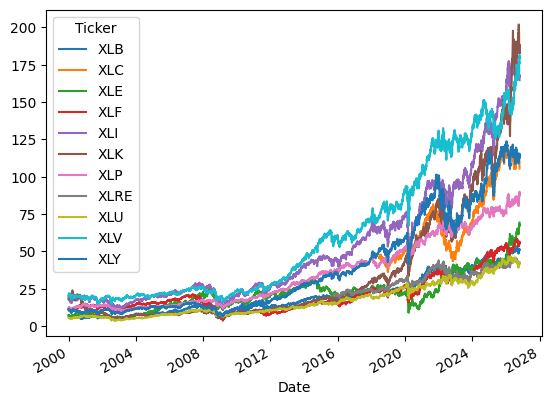

In [21]:
df['Close'].plot()

# Data Handling

[Back to Top](#Begin)

## Log Returns

Log returns are computed under the assumption of *continous time*. It comes from the inverse of the exponential function $e^t$

$\ln(e^t) = t$

Read: the natural-log of $e$ *to the something* is that something.

### Context

Where We Definied Returns Before;

$ r_t = $ return at time period t

$ p_t = $ asset price at time t

$ t = $ time-period eg. daily, weekly, monthly

Asset Return:

$$ r_t = \frac{p_t}{p_{t-1}} - 1$$

Then a series of successive returns of $n$ periods compounded is represented geometrically:

$$r_{\text{cumulative}} := (\prod_{i=1}^{n} 1 + r_i) - 1 = [(1+r_1) \cdot (1+r_2) \cdot (1+r_3) \dots (1+r_n)] - 1$$

This is a more expensive operation, adding 1s to each entry then performing $n$ multiplications.

## Natural Log to the Rescue

Some nice arithmetic properties of using ln() returns is that compounding is additive.

$$\ln\left( \frac{p_t}{p_{t-1}} \right) = \ln( p_t) - \ln( p_{t-1})$$

$$\ln\left( {p_t}\cdot{p_{t-1}} \right) = \ln( p_t) + \ln( p_{t-1})$$

### We Define Log-Returns:

$$r_t := \ln(p_t) - \ln(p_{t-1})$$

$$r_t := \ln(p_{\text{today} } ) - \ln(p_{\text{yesterday} })$$

## Calculation Method

We can apply NumPy's `ln()` function to an entire array of asset prices, then use pandas' `.shift()` method to subract a whole shifted array from the other.

Will look something like this:

```python
log_returns = np.log(data['Close']) - np.log(data['Close']).shift(1)
```

## Missing Data

At this point we will 'produce' a NaN value in our return calculation from our first date, we don't have a previous data point to compute a return from that point. So we'll just drop it. Other stock's will exhbit NaN's, say they weren't listed on an exchange at that point, so no data occurs for them.

## Interpretation

Working with log-returns is nice mathematically. But it will differ from the true return an investor will see if they have their money invested. For example, between 2018-02-26 and 2026-08-28.

### Example

#### AAPL's Average Daily Log-Return: 0.096%

#### AAPL's Average Daily Real Return: 0.123%

# Task 1

# Compute Log-Returns

In [22]:
log_returns = np.log(df['Close']) - np.log(df['Close']).shift(1)
log_returns

Ticker,XLB,XLC,XLE,XLF,XLI,XLK,XLP,XLRE,XLU,XLV,XLY
Date,,,,,,,,,,,
2000-01-03,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2000-01-04,-0.009674,NaN,-0.019003,-0.044700,-0.028016,-0.052065,-0.028563,NaN,-0.030630,-0.022953,-0.030545
2000-01-05,0.040482,NaN,0.026037,-0.007888,-0.004467,-0.014957,0.017513,NaN,0.024922,-0.009011,-0.012375
2000-01-06,0.025346,NaN,0.037827,0.042980,0.013340,-0.033715,0.018576,NaN,-0.001719,0.003190,0.011306
2000-01-07,-0.000568,NaN,0.010629,0.016416,0.037393,0.017306,0.061467,NaN,0.008564,0.012134,0.046033
...,...,...,...,...,...,...,...,...,...,...,...
2026-10-19,0.000589,-0.002087,-0.006469,-0.008320,-0.006459,0.013480,-0.004690,-0.011690,-0.020343,-0.006017,0.017628
2026-10-20,0.005481,0.000908,0.002504,0.011916,0.000720,-0.002800,0.006173,0.016895,0.012494,0.023463,0.009045
2026-10-21,0.001755,-0.011134,0.002791,0.005727,0.009012,0.016579,-0.007320,-0.007579,0.002861,-0.004906,0.000260


In [23]:
log_returns.isna().sum(), log_returns[log_returns.index > '2018'].isna().sum()

(Ticker
 XLB        1
 XLC     4645
 XLE        1
 XLF        1
 XLI        1
 XLK        1
 XLP        1
 XLRE    3967
 XLU        1
 XLV        1
 XLY        1
 dtype: int64,
 Ticker
 XLB       0
 XLC     117
 XLE       0
 XLF       0
 XLI       0
 XLK       0
 XLP       0
 XLRE      0
 XLU       0
 XLV       0
 XLY       0
 dtype: int64)

## Note on NaN Handling

So far we can just ignore the NaNs. They aren't 'in the way' for calculating log-returns at this point. The 'sanity check' above tells us there isn't large holes in the data. I know that ticker TRMD wasn't listed until 2018 compared to our other tickers. So we are missing data for historical reasons. Plus we will have NaN from calculating returns.

If we know some caclulations will choose to 'ignore NaNs' or 'include NaNs', this is what looking up the code documentation is for.


In [24]:
sum_stats = tools.summary_statistics_table(log_returns)

sum_stats

,XLB,XLC,XLE,XLF,XLI,XLK,XLP,XLRE,XLU,XLV,XLY
Mean,0.000292,0.000395,0.000350,0.000241,0.000328,0.000324,0.000296,0.000260,0.000305,0.000323,0.000344
Median,0.000745,0.001067,0.000821,0.000616,0.000813,0.001063,0.000487,0.000833,0.000942,0.000560,0.000895
Standard-Deviation,0.014826,0.013948,0.018165,0.017757,0.013335,0.016288,0.009439,0.012766,0.012091,0.011206,0.014285
Skewness,-0.211880,-0.456690,-0.649857,-0.159880,-0.332843,0.080895,-0.249878,-1.024017,-0.058911,-0.217870,-0.358832
Kurtosis,6.730035,7.106145,12.215804,15.469194,7.993847,7.074342,8.407362,18.383407,11.484221,9.008331,6.695900
Min,-0.132527,-0.119679,-0.224910,-0.182322,-0.120408,-0.148662,-0.098668,-0.174367,-0.120561,-0.103817,-0.135460
Max,0.131534,0.086087,0.152504,0.152394,0.119126,0.149296,0.081678,0.084158,0.120388,0.113817,0.103351


In [25]:
np.exp(sum_stats.loc['Mean']) - 1

XLB     0.000292
XLC     0.000395
XLE     0.000350
XLF     0.000241
XLI     0.000328
XLK     0.000324
XLP     0.000296
XLRE    0.000260
XLU     0.000305
XLV     0.000323
XLY     0.000344
Name: Mean, dtype: float64

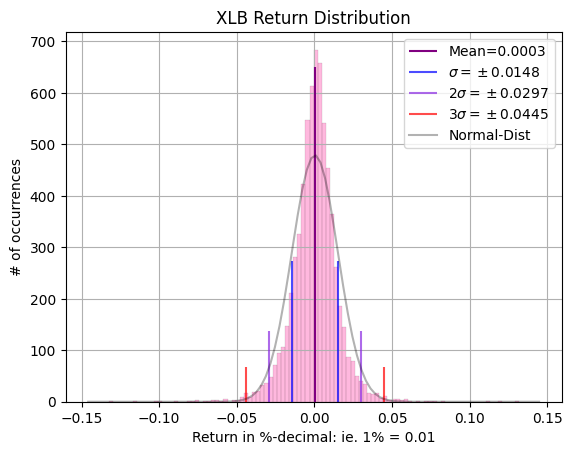

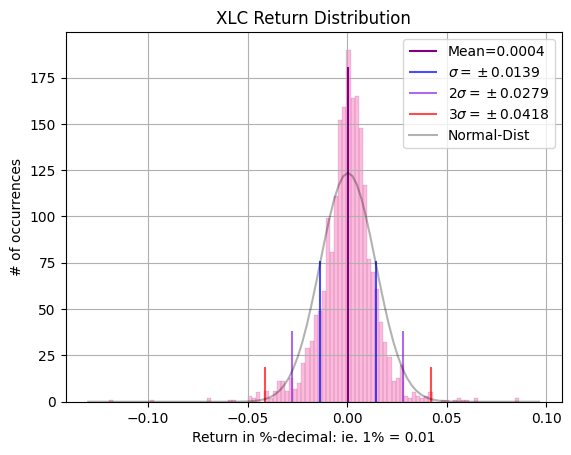

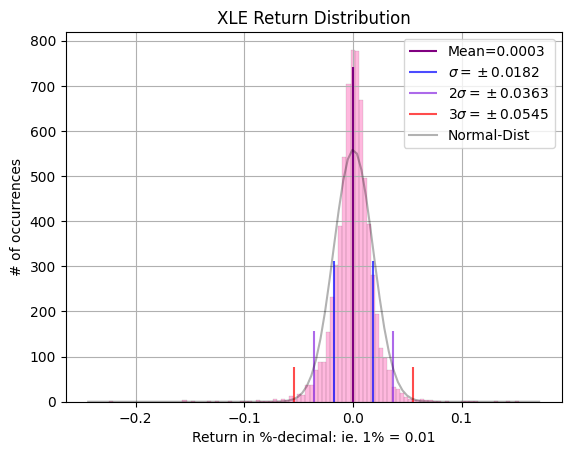

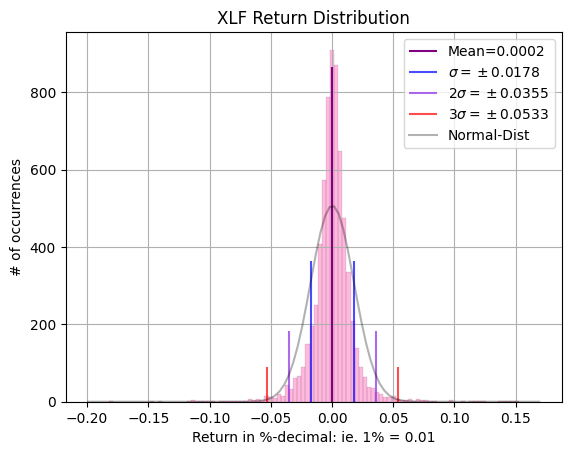

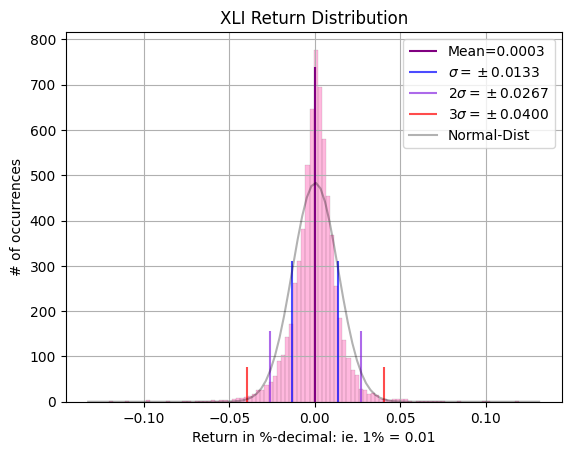

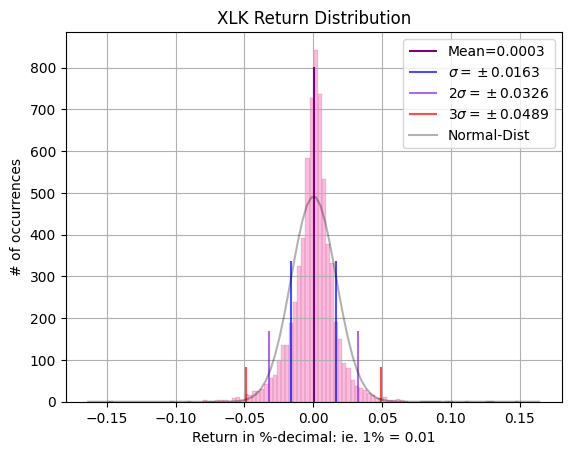

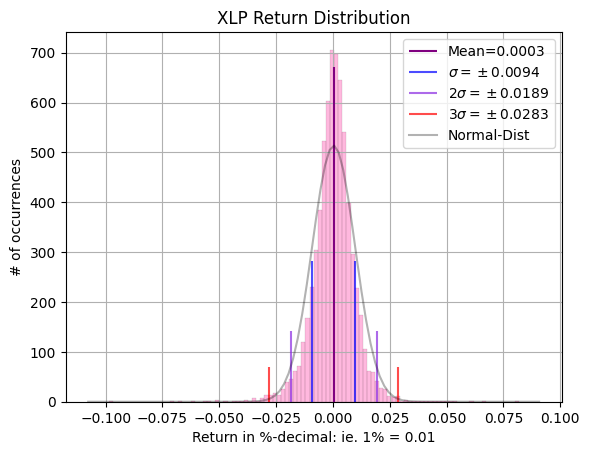

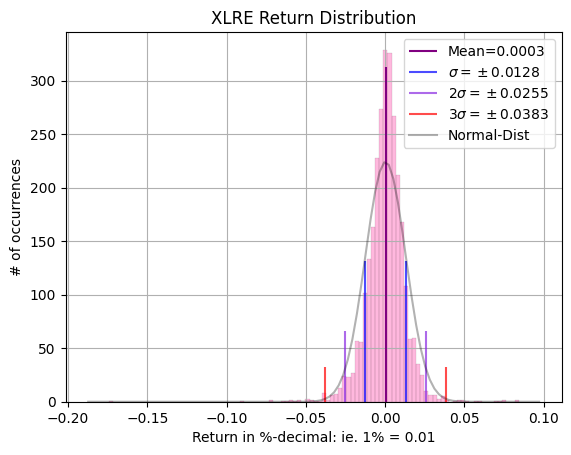

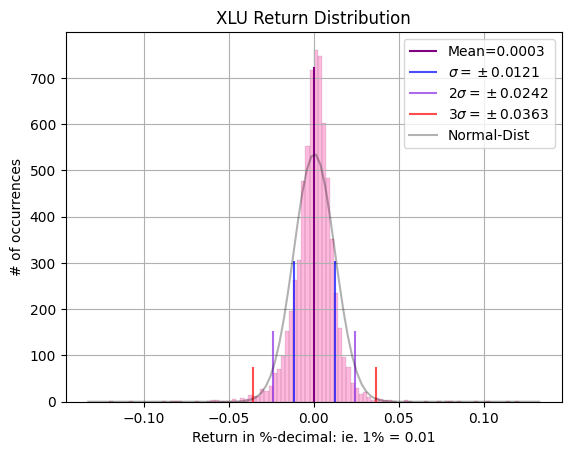

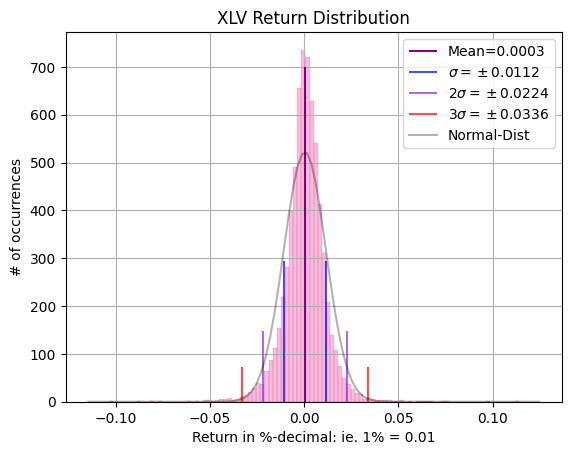

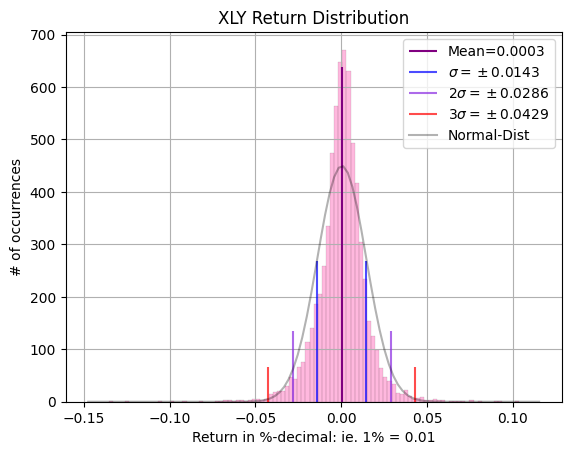

In [27]:
tools.return_histograms(log_returns)

# Task 2

# Annual Volatility

Since log-returns are additive for compounding. We just need to group by year and sum for annualized returns across our time period.

Volatility I will elect to take rolling 90-day windows daily, then compute the average annually, then scale up to annualized by multiplying by $\sqrt{252}.$ Because volatility scales by $\sqrt{\text{time}}$.



In [28]:
df_vol = log_returns.groupby(log_returns.index.year).std() * np.sqrt(252)
df_vol

Ticker,XLB,XLC,XLE,XLF,XLI,XLK,XLP,XLRE,XLU,XLV,XLY
Date,,,,,,,,,,,
2000,0.309386,NaN,0.285607,0.331983,0.245537,0.434862,0.250427,NaN,0.227324,0.261982,0.319639
2001,0.270129,NaN,0.258497,0.252794,0.269053,0.469465,0.188387,NaN,0.192516,0.251774,0.292418
2002,0.288892,NaN,0.288284,0.311292,0.282543,0.417713,0.194693,NaN,0.323599,0.258131,0.288575
2003,0.187335,NaN,0.159788,0.197232,0.176811,0.251905,0.135605,NaN,0.165744,0.164384,0.205605
2004,0.170972,NaN,0.178713,0.122632,0.127967,0.173093,0.098850,NaN,0.119089,0.128692,0.130268
2005,0.159742,NaN,0.256584,0.118993,0.117858,0.121619,0.090383,NaN,0.144730,0.104497,0.130591
2006,0.178026,NaN,0.249429,0.116614,0.120169,0.141538,0.087004,NaN,0.112896,0.100437,0.117825
2007,0.225392,NaN,0.250980,0.240719,0.160724,0.163587,0.108563,NaN,0.174901,0.122304,0.174500
2008,0.471753,NaN,0.614376,0.715477,0.384242,0.408696,0.241994,NaN,0.366882,0.296814,0.439412


In [29]:
df_yearly = df['Close'].groupby(df.index.year)

In [30]:
yearly_returns = {}

for year in df_yearly:
    yr = year[0]
    df1 = year[1]
    

    lg_rtn = np.log(df1) - np.log(df1).shift(1)

    yearly_returns.update({yr: lg_rtn.sum()})

yearly_return_summary = pd.DataFrame(yearly_returns).T
yearly_return_summary = np.exp(yearly_return_summary) - 1



# Annual Return Summary

Below is a table of annual returns.

## Notable Years:

- 2000 was the Dot-Com era crash that led to large negative returns in technology companies like Apple.
- 2008 was the Great Financial Crisis, so we see stocks with a large negative return that year
- 2020, although Intra-Year 2020 saw a massive crash in Q1, the stock market recovered and rallied as a whole throughout the year as liquidity was pumped in the system and new market participants took discretionary money on stock trading, (ie. Robinhood stock-pickers).
- 2022 we can see the 'Mini Bear Market' of interest rate hiking following COVID



Calculation:

To take log-returns back into percentage returns, we need to exponentiate them.

$$r_{\text{Compounded}} = e^{r_{\text{log}} } - 1$$

In [31]:
yearly_return_summary

Ticker,XLB,XLC,XLE,XLF,XLI,XLK,XLP,XLRE,XLU,XLV,XLY
2000,-0.142583,0.000000,0.268888,0.307566,0.095412,-0.435175,0.270945,0.000000,0.255465,-0.100404,-0.142871
2001,0.041926,0.000000,-0.183253,-0.068147,-0.063743,-0.186440,-0.087289,0.000000,-0.116745,0.033830,0.129368
2002,-0.060304,0.000000,-0.140377,-0.146387,-0.245730,-0.396750,-0.198100,0.000000,-0.297776,-0.015789,-0.189151
2003,0.339032,0.000000,0.232182,0.259131,0.285487,0.315640,0.090942,0.000000,0.235623,0.118956,0.322223
2004,0.140480,0.000000,0.339839,0.110175,0.178394,0.051218,0.089460,0.000000,0.239046,0.010385,0.138569
2005,0.051411,0.000000,0.455487,0.065884,0.036494,0.005408,0.028419,0.000000,0.177385,0.076642,-0.059606
2006,0.159147,0.000000,0.127144,0.169318,0.127622,0.099993,0.137572,0.000000,0.185882,0.057512,0.171561
2007,0.228969,0.000000,0.418480,-0.195698,0.127845,0.151106,0.119576,0.000000,0.180990,0.071276,-0.140268
2008,-0.435069,0.000000,-0.390705,-0.539958,-0.376934,-0.402979,-0.137963,0.000000,-0.285049,-0.224979,-0.319304
2009,0.429407,0.000000,0.159852,0.162653,0.177088,0.458361,0.126729,0.000000,0.091491,0.171363,0.338665


# Task 3

[Back to Top](#Begin)

# Data Visualization

# Data Visualization

<Axes: title={'center': 'Cumulative Return 2018-2026'}, xlabel='Date'>

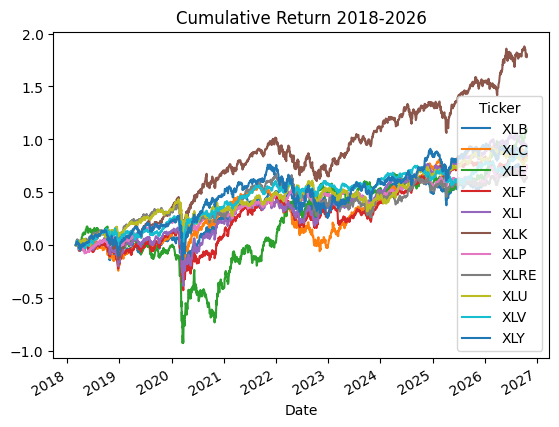

In [32]:
log_returns[log_returns.index > '03-01-2018'].cumsum().plot(title='Cumulative Return 2018-2026')

<Axes: title={'center': 'Rolling 90-Day Volatility'}, xlabel='Date'>

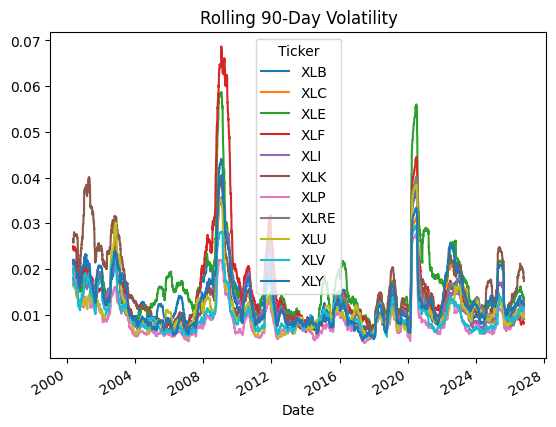

In [33]:
log_returns.rolling(window=90).std().plot(title='Rolling 90-Day Volatility')

## Correlation Matrix

In [35]:
log_returns.corr()

Ticker,XLB,XLC,XLE,XLF,XLI,XLK,XLP,XLRE,XLU,XLV,XLY
Ticker,,,,,,,,,,,
XLB,1.000000,0.646519,0.675911,0.706546,0.824636,0.614886,0.583809,0.647176,0.521762,0.630207,0.721803
XLC,0.646519,1.000000,0.412002,0.663857,0.666752,0.776353,0.522465,0.576871,0.410007,0.610142,0.804859
XLE,0.675911,0.412002,1.000000,0.582137,0.638567,0.446655,0.448478,0.424604,0.475293,0.473182,0.508681
XLF,0.706546,0.663857,0.582137,1.000000,0.787813,0.624240,0.572597,0.624653,0.494032,0.621854,0.739198
XLI,0.824636,0.666752,0.638567,0.787813,1.000000,0.736374,0.623750,0.659498,0.552083,0.704082,0.802626
XLK,0.614886,0.776353,0.446655,0.624240,0.736374,1.000000,0.441295,0.527758,0.431792,0.626628,0.735980
XLP,0.583809,0.522465,0.448478,0.572597,0.623750,0.441295,1.000000,0.671172,0.602085,0.614156,0.588977
XLRE,0.647176,0.576871,0.424604,0.624653,0.659498,0.527758,0.671172,1.000000,0.724915,0.628368,0.609353
XLU,0.521762,0.410007,0.475293,0.494032,0.552083,0.431792,0.602085,0.724915,1.000000,0.525697,0.473629


# Task 4
[Back To Top](#Begin)

## Written Assesment

Presented here is a dynamic and interactive data analysis document. The user can build a portfolio of tickers to perfrom analysis and run the coding cells producing analysis. It all works sequentially, so one can perform another analysis by just going back to the top and choosing a different date range and set of tickers.

Comparing 2-3 stocks, intially I chose Apple, Lockheed Martin, and TORM ( A shipping tanker company). These different tickers exhibit different return and volatility characteristics. You can see that Lockheed Martin exhibits the lowest volatility, as a large stable company in the defense sector, this makes sense. Compared to Apple in the technology sector, we can see Apple's higher-cumulative return matches their higher volatility.

From a macroeconomic perspective you can see the impact of large exogenous events on all of these stocks. Most notably 2000 era Dot-Com crash in Apple. Volatility spikes and negative returns in 2007,2008 due to the Great Financial Crisis. You can also note 2020 COVID-era crash and subsequent rally, followed by 2022 interest-rate hiking adding volatility. More recently you can see 2025 "Liberation Day" volatility spikes from President Trump's aggressive tarrif policy announcements. As an tanker company that deals in oil-markets, you can see Torm's stock rally during 2022 Russian oil embargo, and sinking of oil vessels in Red Sea and 2026 war on Iran. TRMD's exposure to these regional crises has been limited, while their company has benefited from the higher-price point demanded in international markets for shipping tankers.